# Diabetic readmission analysis using advanced ML models

# Project Introduction: Goal and Scope

Hospital readmission can be influenced by many factors, including a patient’s health, previous hospital visits, diagnoses, medications, and details of the current admission. This project uses machine learning to explore whether information recorded for a hospital encounter can help distinguish encounters with and without a positive `readmission_flag`.

The project applies both **baseline and advanced machine learning methods**. Logistic regression provides an interpretable starting point. Support vector machines, Random Forest, and XGBoost are used to examine whether more flexible methods can identify patterns that a linear model may miss. K-Means clustering and principal component analysis (PCA) add unsupervised methods for exploring encounter groups and summarizing patterns across many features.

The goal is to compare these methods, understand the patterns they find, and assess how well they predict the readmission label. The analysis describes associations in the data; it does not show that any patient characteristic or hospital action causes readmission. Findings also depend on how the dataset defines `readmission_flag` and what information is available for each encounter.

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix)
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance

from diabetes_ml import (load_data, clean_data, prepare_data, evaluate_model,
                         train_regression_models, train_ml_models, perform_clustering,
                         perform_pca, coefficient_table, coefficient_stability_cv, compare_pca_cv,
                         permutation_importance_table,
                         train_neural_network)
DATA_PATH = Path(r"C:\Users\nardo\OneDrive\Desktop\Data_science_project\Project_one\Diabetic_data_analysis_project\Data_source\clean_data\diabetes_clean.csv")
RANDOM_STATE = 42




### Setup and Reproducibility

This cell imports the libraries and reusable functions used throughout the project, sets the location of the cleaned diabetes dataset, and fixes a random seed for reproducible results. The `diabetes_ml.py` helper file must be available in the notebook’s Python environment, and `DATA_PATH` should point to the cleaned CSV file.

The project uses these tools to prepare and explore the data, train and evaluate supervised models, compare regularized and unregularized Logistic Regression, analyze clusters and PCA, and examine model explanations. The models and results are introduced in the following sections.

## Milestone One: Baseline Analysis Using Logistic Regression

This milestone establishes Logistic Regression as a baseline for predicting the readmission label. It compares an unregularized model with L1 (Lasso), L2 (Ridge), and Elastic Net regularization.

The comparison examines whether regularization improves predictive performance and coefficient stability when working with many encoded features. These results provide a baseline for evaluating the advanced supervised models in later milestones.

In [14]:
df = load_data(DATA_PATH)
df, audit = clean_data(df)

print("Dataset shape:", df.shape)
print("Duplicate rows:", audit["duplicate_rows"])

print("Target counts:")
display(audit["target_counts"])

print("Target proportions:")
display(audit["target_rate"].round(3))

print("Columns with the most missing values:")
display(audit["missing_by_column"].head(15))

Dataset shape: (10000, 59)
Duplicate rows: 0
Target counts:


readmission_flag
0    6035
1    3965
Name: count, dtype: int64

Target proportions:


readmission_flag
0    0.604
1    0.396
Name: proportion, dtype: float64

Columns with the most missing values:


weight                      9592
max_glu_serum               9336
A1Cresult                   8379
utilization_group           6471
payer_code                  5341
medical_specialty           4100
admission_source_id          936
admission_type_id            721
discharge_disposition_id     469
race                         221
diag_3                       208
diag_3_desc                  208
diag_2_desc                   59
diag_2                        59
diag_1                         2
dtype: int64

In [15]:
X, y, preprocessor = prepare_data(df)

assert "readmission_flag" not in X.columns, (
    "The target column must not be included among the model features."
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Number of features:", X.shape[1])
print("Training encounters:", len(X_train))
print("Test encounters:", len(X_test))
print("Positive rate in training set:", round(y_train.mean(), 3))
print("Positive rate in test set:", round(y_test.mean(), 3))

Number of features: 48
Training encounters: 8000
Test encounters: 2000
Positive rate in training set: 0.396
Positive rate in test set: 0.396


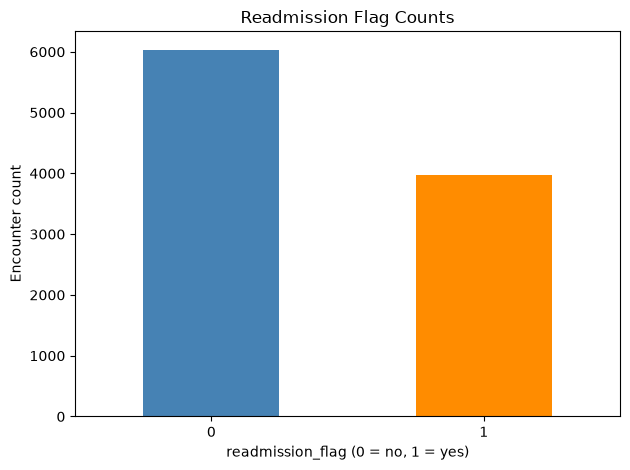

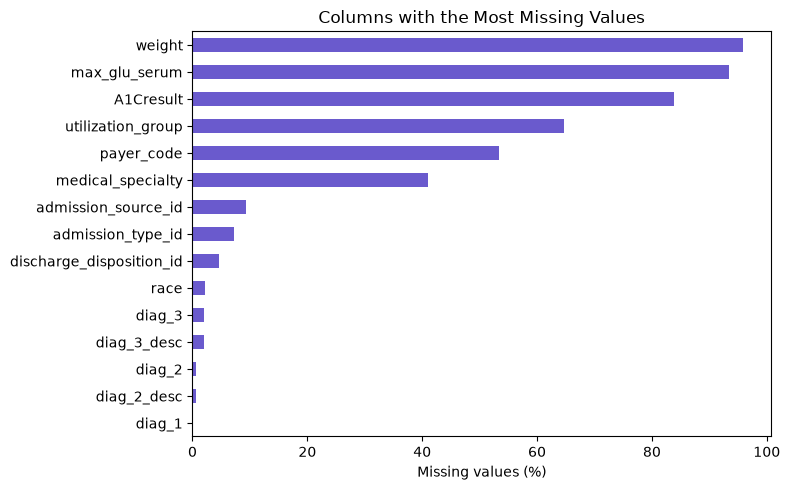

In [20]:
# Basic exploratory plots: target balance and missingness in the 15 most-missing columns.
df['readmission_flag'].value_counts().sort_index().plot(kind='bar', color=['steelblue', 'darkorange'])
plt.title('Readmission Flag Counts')
plt.xlabel('readmission_flag (0 = no, 1 = yes)')
plt.ylabel('Encounter count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

missing_pct = (df.isna().mean() * 100).sort_values(ascending=False).head(15).sort_values()
missing_pct.plot(kind='barh', figsize=(8, 5), color='slateblue')
plt.title('Columns with the Most Missing Values')
plt.xlabel('Missing values (%)')
plt.tight_layout()
plt.show()

In [12]:
regression_models, regression_cv = train_regression_models(
    X_train,
    y_train,
    preprocessor,
)

print("Cross-validation results:")
display(regression_cv)

Cross-validation results:


,model,cv_roc_auc,best_parameters
0,Logistic Regression baseline,0.664437,{}
1,Logistic Regression L2,0.682901,"{'model__C': 0.1, 'model__l1_ratio': 0}"
2,Logistic Regression L1,0.681755,"{'model__C': 0.1, 'model__l1_ratio': 1}"
3,Logistic Regression Elastic Net,0.683502,"{'model__C': 0.1, 'model__l1_ratio': 0.25}"


In [16]:
print("Largest L2 Logistic Regression coefficients:")
display(
    coefficient_table(
        regression_models["Logistic Regression L2"],
        top_n=20,
    )
)

Largest L2 Logistic Regression coefficients:


,feature,coefficient,absolute_coefficient
55,categorical__discharge_disposition_id_Expired,-1.635308,1.635308
247,categorical__diag_1_295,0.591779,0.591779
50,categorical__discharge_disposition_id_Discharg...,0.571734,0.571734
32,categorical__weight_[75-100),-0.571547,0.571547
122,categorical__medical_specialty_Radiologist,0.563784,0.563784
102,categorical__medical_specialty_ObstetricsandGy...,-0.525031,0.525031
56,categorical__discharge_disposition_id_Hospice ...,-0.512213,0.512213
57,categorical__discharge_disposition_id_Hospice ...,-0.426919,0.426919
231,categorical__diag_1_278,-0.424523,0.424523
62,categorical__admission_source_id_Emergency Room,0.387033,0.387033


In [17]:
stability = coefficient_stability_cv(
    X_train,
    y_train,
    preprocessor,
    C=0.1,
    l1_ratio=0.0,
)

print("Features with the most variable coefficients across folds:")
display(stability.head(20))

Features with the most variable coefficients across folds:


,feature,mean_coefficient,coefficient_std,sign_consistency
1302,categorical__diag_3_V45,0.043626,0.153956,0.8
91,categorical__medical_specialty_Gastroenterology,0.111697,0.153409,0.8
1099,categorical__diag_3_493,0.211518,0.141038,0.8
1213,categorical__diag_3_781,0.143579,0.131233,0.8
585,categorical__diag_2_250.6,0.313784,0.124870,1.0
1134,categorical__diag_3_578,-0.015444,0.122122,0.6
104,categorical__medical_specialty_Orthopedics,-0.212485,0.120483,1.0
599,categorical__diag_2_272,0.025996,0.119033,0.6
717,categorical__diag_2_491,0.079026,0.118364,0.8
41,categorical__discharge_disposition_id_Discharg...,-0.054396,0.118275,0.6


In [18]:
def get_coefficient_series(fitted_model):
    """Return model coefficients indexed by their transformed feature names."""
    estimator = (
        fitted_model.steps[-1][1]
        if hasattr(fitted_model, "steps")
        else fitted_model
    )

    fitted_preprocessor = (
        fitted_model.named_steps["preprocessor"]
        if hasattr(fitted_model, "named_steps")
        and "preprocessor" in fitted_model.named_steps
        else preprocessor
    )

    coefficients = np.asarray(estimator.coef_).ravel()
    feature_names = fitted_preprocessor.get_feature_names_out()

    if len(feature_names) != len(coefficients):
        raise ValueError(
            f"Found {len(feature_names)} feature names but "
            f"{len(coefficients)} coefficients."
        )

    return pd.Series(coefficients, index=feature_names)


baseline_name = "Logistic Regression baseline"
l2_name = "Logistic Regression L2"

print("Available models:", list(regression_models))

coef_compare = pd.concat(
    [
        get_coefficient_series(regression_models[baseline_name]).rename(
            "unregularized"
        ),
        get_coefficient_series(regression_models[l2_name]).rename(
            "L2_regularized"
        ),
    ],
    axis=1,
).fillna(0.0)

coef_compare["absolute_change"] = (
    coef_compare["L2_regularized"] - coef_compare["unregularized"]
).abs()

print("Coefficient summary:")
display(
    pd.DataFrame(
        {
            "measure": [
                "Nonzero coefficients",
                "Median absolute coefficient",
                "Maximum absolute coefficient",
            ],
            "Unregularized": [
                (coef_compare["unregularized"].abs() > 1e-8).sum(),
                coef_compare["unregularized"].abs().median(),
                coef_compare["unregularized"].abs().max(),
            ],
            "L2 regularized": [
                (coef_compare["L2_regularized"].abs() > 1e-8).sum(),
                coef_compare["L2_regularized"].abs().median(),
                coef_compare["L2_regularized"].abs().max(),
            ],
        }
    )
)

print("Features with the largest coefficient changes:")
display(
    coef_compare.sort_values("absolute_change", ascending=False)
    .head(20)
    .round(4)
)

Available models: ['Logistic Regression baseline', 'Logistic Regression L2', 'Logistic Regression L1', 'Logistic Regression Elastic Net']
Coefficient summary:


,measure,Unregularized,L2 regularized
0,Nonzero coefficients,1468.000000,1468.000000
1,Median absolute coefficient,0.277527,0.047543
2,Maximum absolute coefficient,3.281464,1.635308


Features with the largest coefficient changes:


,unregularized,L2_regularized,absolute_change
categorical__discharge_disposition_id_Expired,-3.2815,-1.6353,1.6462
categorical__medical_specialty_Cardiology-Pediatric,1.4992,0.1879,1.3112
categorical__diag_2_721,1.4783,0.2172,1.2612
categorical__diag_3_135,-1.3156,-0.2107,1.1049
categorical__diag_1_295,1.5850,0.5918,0.9932
categorical__diag_1_290,-1.2034,-0.2144,0.9890
categorical__discharge_disposition_id_Hospice / home,-1.4895,-0.5122,0.9773
categorical__diag_2_250.13,1.1393,0.1642,0.9751
categorical__discharge_disposition_id_Hospice / medical facility,-1.3728,-0.4269,0.9459
categorical__diag_1_785,-1.1634,-0.2245,0.9389


### Milestone One: Interpretation

Five-fold stratified cross-validation compares the unregularized Logistic Regression baseline with L1, L2, and Elastic Net models. The baseline ROC-AUC was 0.6644, compared with 0.6818 for L1, 0.6829 for L2, and 0.6835 for Elastic Net. In this run, regularization improved the models’ average ability to rank positive encounters above negative encounters. Elastic Net had the highest score, although its advantage over L2 was very small.

The coefficient comparison shows that L2 regularization shrank coefficient magnitudes toward zero. Both models had 1,468 nonzero coefficients, while the median absolute coefficient decreased from 0.2775 in the unregularized model to 0.0475 in the L2 model. L2 reduces coefficient magnitudes but generally does not eliminate coefficients; L1 can set some coefficients to zero.

A positive coefficient corresponds to higher fitted log-odds of a positive readmission label, and a negative coefficient corresponds to lower fitted log-odds, relative to the encoded reference category and with other features held constant. These are model associations, not evidence of causation. Interpret large coefficients cautiously, especially for rare categories.

Cross-validation results are used to compare the models during training. The held-out test set should be used separately to assess final performance on encounters that were not used to fit or tune the models.

## Milestone Two: Comparing SVM, XGBoost, and Random Forest

This milestone compares three advanced supervised learning methods with the Logistic Regression baseline. A Support Vector Machine (SVM) tests linear and nonlinear decision boundaries. Random Forest and XGBoost use collections of decision trees to model nonlinear relationships and interactions between features.

The models are tuned using stratified cross-validation on the training data. Their predictive performance is then evaluated on the held-out test set using accuracy, precision, recall, F1-score, ROC-AUC, PR-AUC, and confusion matrices. The comparison examines whether these methods improve prediction enough to justify their added complexity. A more advanced model is not automatically a better choice; the results and project goal determine which model is most appropriate.

In [21]:
ml_models, ml_cv = train_ml_models(X_train, y_train, preprocessor, include_xgboost=True)

# Tune a Random Forest by the same cross-validation ROC-AUC criterion.
rf_pipe = Pipeline([('preprocessor', preprocessor),
                    ('model', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])
rf_search = GridSearchCV(
    rf_pipe,
    {'model__n_estimators': [200, 300],
     'model__max_depth': [None, 12, 24],
     'model__min_samples_leaf': [1, 2, 4]},
    scoring='roc_auc', cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1, refit=True
)
rf_search.fit(X_train, y_train)
ml_models['Random Forest'] = rf_search.best_estimator_
rf_cv = pd.DataFrame([{'model': 'Random Forest', 'cv_roc_auc': rf_search.best_score_,
                       'best_parameters': rf_search.best_params_}])

all_models = {**regression_models, **ml_models}
cv_table = pd.concat([regression_cv, ml_cv, rf_cv], ignore_index=True)
print('Training cross-validation results:')
display(cv_table.sort_values('cv_roc_auc', ascending=False).reset_index(drop=True))

C:\Users\nardo\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\nardo\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Training cross-validation results:


,model,cv_roc_auc,best_parameters
0,XGBoost,0.693062,"{'model__subsample': 0.8, 'model__n_estimators..."
1,Random Forest,0.692863,"{'model__max_depth': None, 'model__min_samples..."
2,Logistic Regression Elastic Net,0.683502,"{'model__C': 0.1, 'model__l1_ratio': 0.25}"
3,Logistic Regression L2,0.682901,"{'model__C': 0.1, 'model__l1_ratio': 0}"
4,Logistic Regression L1,0.681755,"{'model__C': 0.1, 'model__l1_ratio': 1}"
5,RBF SVM,0.679441,"{'model__C': 1, 'model__gamma': 'scale', 'mode..."
6,Linear SVM,0.673123,"{'model__C': 0.1, 'model__kernel': 'linear'}"
7,Logistic Regression baseline,0.664437,{}


In [22]:
test_results = []
for name, fitted_model in all_models.items():
    test_results.append(evaluate_model(name, fitted_model, X_test, y_test))

comparison = pd.DataFrame(test_results)
metric_columns = ['model', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc']
display(comparison[metric_columns].sort_values('roc_auc', ascending=False).round(3))

for row in test_results:
    print('\n', row['model'])
    print(row['confusion_matrix'])

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
7,Random Forest,0.662,0.659,0.306,0.418,0.692,0.584
6,XGBoost,0.658,0.619,0.362,0.457,0.688,0.587
1,Logistic Regression L2,0.666,0.634,0.376,0.472,0.686,0.593
3,Logistic Regression Elastic Net,0.668,0.651,0.353,0.458,0.686,0.591
2,Logistic Regression L1,0.660,0.642,0.323,0.430,0.680,0.583
4,Linear SVM,0.654,0.634,0.305,0.412,0.677,0.586
5,RBF SVM,0.654,0.639,0.290,0.399,0.675,0.572
0,Logistic Regression baseline,0.644,0.569,0.420,0.483,0.666,0.567



 Logistic Regression baseline
[[955 252]
 [460 333]]

 Logistic Regression L2
[[1035  172]
 [ 495  298]]

 Logistic Regression L1
[[1064  143]
 [ 537  256]]

 Logistic Regression Elastic Net
[[1057  150]
 [ 513  280]]

 Linear SVM
[[1067  140]
 [ 551  242]]

 RBF SVM
[[1077  130]
 [ 563  230]]

 XGBoost
[[1030  177]
 [ 506  287]]

 Random Forest
[[1081  126]
 [ 550  243]]


### Milestone Two: Test-Set Evaluation

The table compares all models on the same held-out test set. Their ROC-AUC scores range from 0.666 to 0.692, indicating modest ability to rank encounters with a positive readmission label above those without one. Random Forest achieved the highest ROC-AUC (0.692), followed closely by XGBoost (0.688) and the regularized Logistic Regression models (0.680–0.686). The differences are small, so this test-set comparison alone does not establish that one model is definitively superior.

The results depend on which measure matters for the project goal. Elastic Net had the highest accuracy (0.668). L2 Logistic Regression had the highest PR-AUC (0.593), while the unregularized Logistic Regression baseline had the highest recall (0.420) and F1-score (0.483) at the evaluated classification threshold. The baseline therefore identified a larger share of positive encounters, but it also had lower precision (0.569), meaning more of its positive predictions were incorrect.

The confusion matrices show this trade-off. For the baseline, the matrix `[[955, 252], [460, 333]]` means it correctly classified 955 negative encounters and 333 positive encounters, while missing 460 positive encounters. Random Forest had the highest ROC-AUC, but its matrix `[[1081, 126], [550, 243]]` shows that it missed more positive encounters at this threshold. XGBoost found more positive encounters than Random Forest (287 versus 243) but still missed 506.

Overall, the advanced models did not clearly outperform the Logistic Regression models on every measure. Random Forest had the strongest ROC-AUC, while the Logistic Regression baseline had the strongest recall and F1-score. The preferred model depends on the project priority: if identifying more positive encounters is the priority, recall and the number of missed positives deserve particular attention. The classification threshold should be chosen using validation data and an explicit balance between missed cases and false alerts. These results describe predictive performance on this test set; they do not demonstrate clinical usefulness or causation.

## Milestone Three: Unsupervised Learning with K-Means and PCA

Unsupervised learning broadens the project beyond predicting a known outcome. It can reveal structure in the encounter data that may not be obvious from individual variables, such as groups of encounters with similar utilization or hospital-stay patterns. Exploring these groups can generate new questions, help summarize patient populations, and provide context for the supervised models. In this project, K-Means is used to discover and describe possible groups, then compare their profiles and readmission rates. These findings are exploratory and should be interpreted alongside the predictive results.

This milestone explores patterns in the encounter data without using the readmission label to create groups. K-Means clustering groups encounters with similar utilization and hospital-stay characteristics. The resulting cluster profiles and readmission rates are then compared to see whether the groups differ descriptively.

Principal Component Analysis (PCA) reduces the encoded feature set to two components for visualization. The plot helps summarize patterns across many features, while cross-validation compares predictive performance with and without PCA. Clusters and visual patterns are exploratory: they do not prove that distinct clinical patient types exist or that cluster membership causes readmission.

Unsupervised learning is included because the project guideline asks whether the encounters contain meaningful groups, in addition to predicting readmission with labeled data. Unlike supervised models, K-Means does not use the readmission label when forming clusters. This lets us explore whether encounters with similar utilization and hospital-stay patterns also show different readmission rates. The analysis is exploratory and complements the prediction models; it does not replace them or establish that a cluster causes readmission.

### K-Means: Purpose and Cluster Interpretation

K-Means is an unsupervised learning method, so it forms groups using similarities in the selected encounter features without using the readmission label to create those groups. It adds a different perspective to the project: instead of predicting a known outcome, it helps explore whether encounters naturally form groups with different characteristics. The readmission rates can then be compared across those groups.

The analysis identified three clusters containing 994, 2,898, and 6,108 encounters. In the displayed results, Cluster 0 has a readmission rate of 64.79%, while Cluster 1 has a rate of 42.13%. Cluster 0 also has a median of 2 prior inpatient visits, compared with 0 for Cluster 1. Cluster 1 has higher displayed medians for hospital stay (7 days), lab procedures (55), procedures (2), and medications (22).

These profiles suggest that the clusters capture different patterns of hospital use and care. However, the pasted output does not include the complete profile or readmission rate for Cluster 2, so the comparison across all three groups is incomplete. K-Means clusters are exploratory groupings based on the selected features; they are not confirmed clinical categories, and differences in readmission rates do not show that cluster membership or any individual feature causes readmission.

Silhouette scores: {2: 0.218, 3: 0.218, 4: 0.159, 5: 0.171, 6: 0.172}
Selected k for review: 3


,encounters,time_in_hospital_median,num_lab_procedures_median,num_procedures_median,num_medications_median,number_outpatient_median,number_emergency_median,number_inpatient_median,number_diagnoses_median,readmission_rate
cluster,,,,,,,,,,
0,994,4.0,48.0,0.0,15.0,0.0,0.0,2.0,9.0,64.79
1,2898,7.0,55.0,2.0,22.0,0.0,0.0,0.0,9.0,42.13
2,6108,3.0,39.0,0.0,11.0,0.0,0.0,0.0,6.0,34.38


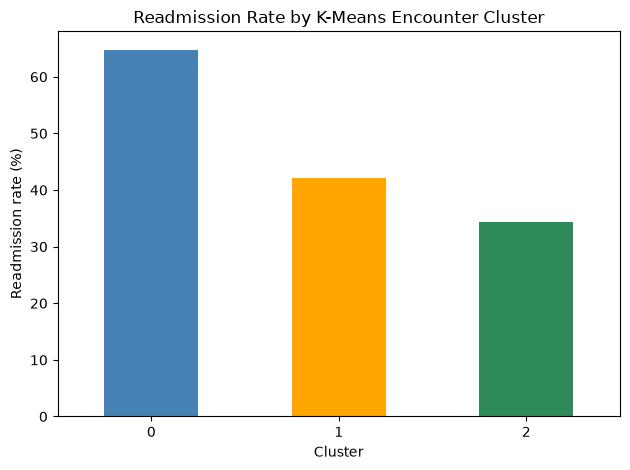

In [23]:
cluster_result = perform_clustering(df)
print('Silhouette scores:', {k: round(v, 3) for k, v in cluster_result['scores'].items()})
print('Selected k for review:', cluster_result['best_k'])
display(cluster_result['profile'].round(2))

cluster_result['profile']['readmission_rate'].plot(kind='bar', color=['steelblue', 'orange', 'seagreen'])
plt.title('Readmission Rate by K-Means Encounter Cluster')
plt.xlabel('Cluster')
plt.ylabel('Readmission rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### K-Means Cluster Interpretation

K-Means divided the 10,000 encounters into three groups of different sizes: Cluster 0 contains 994 encounters, Cluster 1 contains 2,898, and Cluster 2 contains 6,108. The profiles suggest that the clusters differ in hospital stay, procedures, medications, and prior inpatient use.

Among the rates shown, Cluster 0 has the highest readmission rate at 64.79%. Its median prior inpatient visits is 2, compared with 0 for Cluster 1. Cluster 1 has a readmission rate of 42.13% and the highest median values shown for hospital stay (7 days), lab procedures (55), procedures (2), and medications (22). These are descriptive differences between the groups, not evidence that those characteristics cause readmission.

The pasted output does not show Cluster 2’s full profile or readmission rate, so a complete comparison of all three clusters is not yet possible. Include the full Cluster 2 row before drawing a conclusion about which group has the lowest readmission rate. Overall, K-Means provides a way to summarize patterns across encounters and suggest groups for further investigation; the clusters should not be treated as established clinical patient types.

## PCA visualization

PCA combines scaled and encoded training features into two principal components. We fit preprocessing and PCA using training data, then transform test data. The plot is an exploratory projection; it does not prove clusters are distinct. PCA's effect on predictive performance must be checked using cross-validation on training data.

Variance explained by first two components: 22.88 %


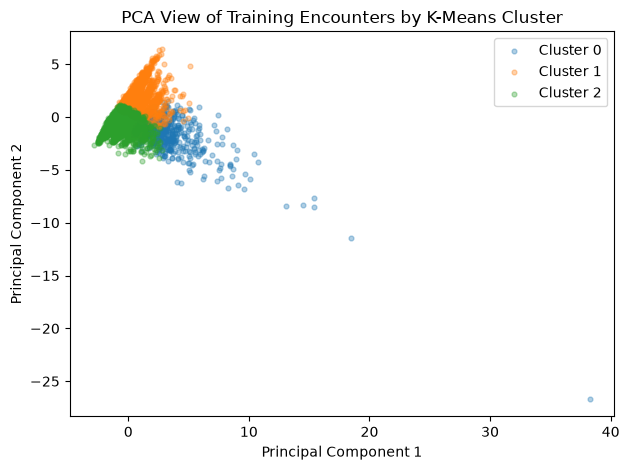

,approach,mean_cv_roc_auc,std_cv_roc_auc
0,"Logistic Regression, no PCA",0.664,0.016
1,"Logistic Regression, PCA (2 components)",0.639,0.010


In [24]:
pca, pca_train, pca_test = perform_pca(X_train, X_test, preprocessor, n_components=2)
print('Variance explained by first two components:', round(pca.explained_variance_ratio_.sum() * 100, 2), '%')

train_plot = pd.DataFrame({'PC1': pca_train[:, 0], 'PC2': pca_train[:, 1],
                           'cluster': cluster_result['data'].loc[X_train.index, 'cluster'].to_numpy()})
for cluster_id in sorted(train_plot['cluster'].unique()):
    part = train_plot[train_plot['cluster'] == cluster_id]
    plt.scatter(part['PC1'], part['PC2'], s=12, alpha=0.35, label=f'Cluster {cluster_id}')
plt.title('PCA View of Training Encounters by K-Means Cluster')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.tight_layout()
plt.show()

# Compare training-fold ROC-AUC with and without two-component PCA.
# This tests predictive performance; the scatter plot alone cannot answer this.
pca_cv_comparison = compare_pca_cv(X_train, y_train, preprocessor, n_components=2)
display(pca_cv_comparison.round(3))


### PCA Interpretation

The first two principal components explain 22.88% of the variation in the encoded and scaled features. This means the two-dimensional plot provides a simplified view of the data, but it does not capture most of its overall variation. Encounters that appear close together in this plot are similar along these two components; encounters that appear separate may still be similar in dimensions not shown.

The plot is useful for visual exploration, but it cannot by itself confirm distinct patient groups or show how well the features predict readmission. PCA is included to summarize high-dimensional data and support visualization. Whether reducing the features to two components helps prediction should be judged using the cross-validation comparison of model performance with and without PCA.

## Milestone Four: Feedforward Neural Network

This milestone uses a feedforward neural network to test whether a more flexible model can learn useful patterns in the encounter data. The network has two hidden layers with 64 and 32 ReLU units, dropout to help limit overfitting, and a sigmoid output layer for binary classification. It is trained using binary cross-entropy loss and the Adam optimizer.

Training and validation loss curves are used to examine how learning progresses and whether the model may be overfitting. The network’s test-set metrics are compared with the other supervised models. Its added complexity is useful only if it provides a meaningful improvement for the project’s prediction goal.

The neural network uses the prepared training features to learn patterns associated with the readmission label. Preprocessing is fit using the training data, and the trained network is then evaluated on the held-out test data. An internal validation split and early stopping help monitor training and identify possible overfitting. The training and validation loss curves show how the model learns, but they do not by themselves establish predictive performance; compare the test-set metrics with those of the other supervised models.

Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.6320 - loss: 0.6511 - roc_auc: 0.6142 - val_accuracy: 0.6413 - val_loss: 0.6284 - val_roc_auc: 0.6712
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6544 - loss: 0.6250 - roc_auc: 0.6751 - val_accuracy: 0.6600 - val_loss: 0.6194 - val_roc_auc: 0.6848
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6711 - loss: 0.6039 - roc_auc: 0.7110 - val_accuracy: 0.6656 - val_loss: 0.6163 - val_roc_auc: 0.6895
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6834 - loss: 0.5815 - roc_auc: 0.7415 - val_accuracy: 0.6712 - val_loss: 0.6183 - val_roc_auc: 0.6929
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7027 - loss: 0.5596 - roc_auc: 0.7666 - val_accuracy: 0.6644 - val_loss: 0.6319 - val_roc_auc: 0.6872
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7208 - loss: 0.5377 - roc_auc: 0.7912 - val_accuracy: 0.6569 - val_loss: 0.6436 - val_ro

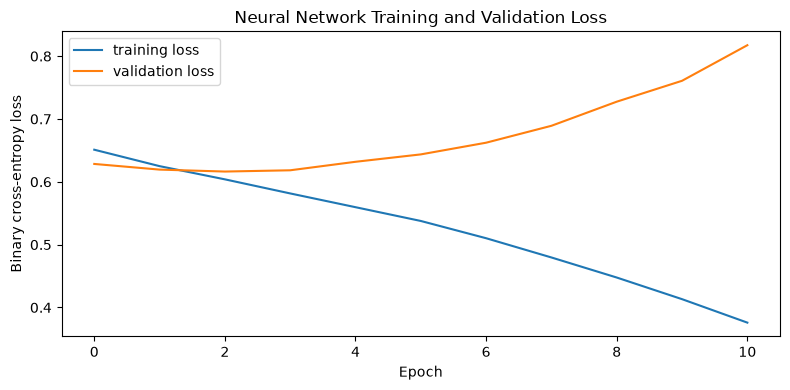

{'model': 'Neural Network', 'accuracy': 0.6585, 'precision': 0.5971731448763251, 'recall': 0.4262295081967213, 'f1': 0.4974245768947756, 'roc_auc': 0.6814536055439528, 'pr_auc': 0.5886241961436066}
Confusion matrix:
 [[979 228]
 [455 338]]


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
7,Random Forest,0.662,0.659,0.306,0.418,0.692,0.584
6,XGBoost,0.658,0.619,0.362,0.457,0.688,0.587
1,Logistic Regression L2,0.666,0.634,0.376,0.472,0.686,0.593
3,Logistic Regression Elastic Net,0.668,0.651,0.353,0.458,0.686,0.591
8,Neural Network,0.658,0.597,0.426,0.497,0.681,0.589
2,Logistic Regression L1,0.660,0.642,0.323,0.430,0.680,0.583
4,Linear SVM,0.654,0.634,0.305,0.412,0.677,0.586
5,RBF SVM,0.654,0.639,0.290,0.399,0.675,0.572
0,Logistic Regression baseline,0.644,0.569,0.420,0.483,0.666,0.567


In [25]:
# If TensorFlow is installed, train the network. This cell raises a clear install message otherwise.
neural_model, neural_history, neural_metrics = train_neural_network(
    X_train, y_train, X_test, y_test, preprocessor, epochs=100, batch_size=64
)

plt.figure(figsize=(8, 4))
plt.plot(neural_history.history['loss'], label='training loss')
plt.plot(neural_history.history['val_loss'], label='validation loss')
plt.title('Neural Network Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Binary cross-entropy loss')
plt.legend()
plt.tight_layout()
plt.show()

print({key: value for key, value in neural_metrics.items() if key != 'confusion_matrix'})
print('Confusion matrix:\n', neural_metrics['confusion_matrix'])

test_results.append(neural_metrics)
comparison = pd.DataFrame(test_results)
display(comparison[metric_columns].sort_values('roc_auc', ascending=False).round(3))

### Neural Network Results and Interpretation

On the held-out test set, the neural network achieved 0.658 accuracy, 0.597 precision, 0.426 recall, an F1-score of 0.497, a ROC-AUC of 0.681, and a PR-AUC of 0.589.

At the evaluated threshold, the neural network had the highest recall and F1-score among the compared models. Its recall of 0.426 means it identified about 42.6% of encounters with a positive readmission label. Its precision of 0.597 means about 59.7% of the encounters it predicted as positive were positive. This shows a trade-off: it identified more positive encounters than the other models, while still producing some false-positive predictions.

The neural network did not have the highest ROC-AUC: Random Forest scored 0.692, compared with 0.681 for the neural network. L2 Logistic Regression had the highest PR-AUC at 0.593, slightly above the neural network’s 0.589. Therefore, the neural network performed well on recall and F1-score, but it did not outperform every other model across all measures.

These results suggest the neural network may be useful when identifying a larger share of positive encounters is a priority. Its complexity should be weighed against the small differences in performance and the easier interpretation of Logistic Regression. Training and validation loss curves should also be reviewed for signs of overfitting. These results describe performance on this test set and do not establish clinical usefulness.

# Milestone Five: Model Evaluation and Comparison

This milestone consolidates the supervised model results and compares their tuned configurations. Hyperparameters are selected using stratified cross-validation on the training data. The selected models are then evaluated on the same held-out test set using accuracy, precision, recall, F1-score, ROC-AUC, PR-AUC, and confusion matrices.

Each metric highlights a different aspect of performance. The comparison helps identify trade-offs and determine which model best fits the project’s goal. No single metric automatically makes a model the best choice.

In [26]:
print("Cross-validation results and selected hyperparameters:")
display(
    cv_table.sort_values("cv_roc_auc", ascending=False)
    .reset_index(drop=True)
)

Cross-validation results and selected hyperparameters:


,model,cv_roc_auc,best_parameters
0,XGBoost,0.693062,"{'model__subsample': 0.8, 'model__n_estimators..."
1,Random Forest,0.692863,"{'model__max_depth': None, 'model__min_samples..."
2,Logistic Regression Elastic Net,0.683502,"{'model__C': 0.1, 'model__l1_ratio': 0.25}"
3,Logistic Regression L2,0.682901,"{'model__C': 0.1, 'model__l1_ratio': 0}"
4,Logistic Regression L1,0.681755,"{'model__C': 0.1, 'model__l1_ratio': 1}"
5,RBF SVM,0.679441,"{'model__C': 1, 'model__gamma': 'scale', 'mode..."
6,Linear SVM,0.673123,"{'model__C': 0.1, 'model__kernel': 'linear'}"
7,Logistic Regression baseline,0.664437,{}


In [27]:
metric_columns = [
    "model",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "pr_auc",
]

print("Held-out test-set comparison:")
display(
    comparison[metric_columns]
    .sort_values("roc_auc", ascending=False)
    .reset_index(drop=True)
    .round(3)
)

Held-out test-set comparison:


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Random Forest,0.662,0.659,0.306,0.418,0.692,0.584
1,XGBoost,0.658,0.619,0.362,0.457,0.688,0.587
2,Logistic Regression L2,0.666,0.634,0.376,0.472,0.686,0.593
3,Logistic Regression Elastic Net,0.668,0.651,0.353,0.458,0.686,0.591
4,Neural Network,0.658,0.597,0.426,0.497,0.681,0.589
5,Logistic Regression L1,0.660,0.642,0.323,0.430,0.680,0.583
6,Linear SVM,0.654,0.634,0.305,0.412,0.677,0.586
7,RBF SVM,0.654,0.639,0.290,0.399,0.675,0.572
8,Logistic Regression baseline,0.644,0.569,0.420,0.483,0.666,0.567


In [28]:
for result in test_results:
    print(f"\n{result['model']}")
    print("Confusion matrix [[TN, FP], [FN, TP]]:")
    print(result["confusion_matrix"])


Logistic Regression baseline
Confusion matrix [[TN, FP], [FN, TP]]:
[[955 252]
 [460 333]]

Logistic Regression L2
Confusion matrix [[TN, FP], [FN, TP]]:
[[1035  172]
 [ 495  298]]

Logistic Regression L1
Confusion matrix [[TN, FP], [FN, TP]]:
[[1064  143]
 [ 537  256]]

Logistic Regression Elastic Net
Confusion matrix [[TN, FP], [FN, TP]]:
[[1057  150]
 [ 513  280]]

Linear SVM
Confusion matrix [[TN, FP], [FN, TP]]:
[[1067  140]
 [ 551  242]]

RBF SVM
Confusion matrix [[TN, FP], [FN, TP]]:
[[1077  130]
 [ 563  230]]

XGBoost
Confusion matrix [[TN, FP], [FN, TP]]:
[[1030  177]
 [ 506  287]]

Random Forest
Confusion matrix [[TN, FP], [FN, TP]]:
[[1081  126]
 [ 550  243]]

Neural Network
Confusion matrix [[TN, FP], [FN, TP]]:
[[979 228]
 [455 338]]


### Milestone Five: Results and Model Comparison

The models show different strengths on the held-out test set. Random Forest achieved the highest ROC-AUC (0.692), followed by XGBoost (0.688). L2 Logistic Regression achieved the highest PR-AUC (0.593), while Elastic Net had the highest accuracy (0.668). The neural network achieved the highest recall (0.426) and F1-score (0.497) among the models in this comparison.

These results show that no model performed best on every measure. Random Forest ranked encounters best across thresholds according to ROC-AUC, while the neural network identified the largest share of positive encounters at the evaluated threshold. L2 Logistic Regression had the strongest PR-AUC, and Elastic Net had the highest accuracy. Model choice therefore depends on the project priority and the relative cost of missed positive cases and false alerts.

The confusion matrices show the numbers of true negatives, false positives, false negatives, and true positives at the evaluated classification threshold. In particular, recall should be considered when missed readmissions are a concern. A model with higher recall may also generate more false positives, so its precision and confusion matrix should be reviewed alongside recall.

The performance differences are modest. The results do not show that the more complex models consistently outperform Logistic Regression. A final recommendation should balance predictive performance with interpretability and complexity, and should be based on the metric most relevant to the project objective. These test-set results are estimates for this dataset and split; they do not establish clinical usefulness or readiness for deployment.

## Milestone Six: Model Explanation and Conclusion

This milestone examines which input features the selected model relies on and summarizes the project’s findings, business relevance, and limitations. Permutation importance measures how much the model’s test-set ROC-AUC changes when one input feature is shuffled. A larger decrease suggests the model relied more on that feature for ranking encounters.

Feature importance describes model behavior in this dataset; it does not show that a feature causes readmission. Logistic Regression coefficients provide a complementary view for the regression models. The final conclusion considers predictive performance alongside interpretability, complexity, and the project’s goal.

Selected using training cross-validation: XGBoost
Held-out test metrics:


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
6,XGBoost,0.658,0.619,0.362,0.457,0.688,0.587


Top permutation importance results:


,feature,importance_mean,importance_std
47,total_prior_visits_engineered,0.035990,0.008428
5,discharge_disposition_id,0.024978,0.003437
19,number_diagnoses,0.021185,0.003734
6,admission_source_id,0.007425,0.001561
10,num_lab_procedures,0.006307,0.003418
2,age,0.005949,0.002002
9,medical_specialty,0.004785,0.001924
12,num_medications,0.003872,0.001213
16,diag_1,0.003724,0.002046
15,number_inpatient,0.003583,0.002694


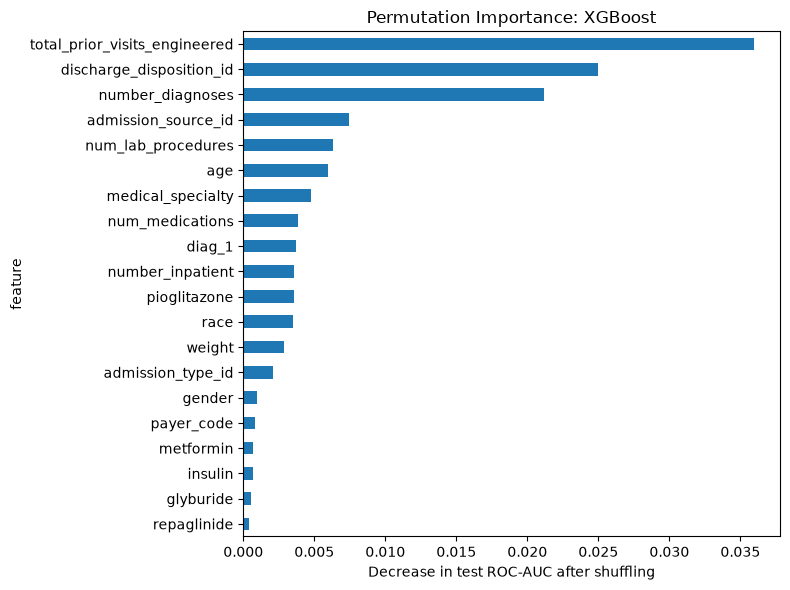

In [29]:
# Select the model with the highest cross-validation ROC-AUC.
# The test set remains reserved for final evaluation and explanation.
cv_results_for_selection = cv_table.dropna(subset=["cv_roc_auc"])

selected_model_name = (
    cv_results_for_selection
    .sort_values("cv_roc_auc", ascending=False)
    .iloc[0]["model"]
)

selected_model = all_models[selected_model_name]

print("Selected using training cross-validation:", selected_model_name)

selected_test_metrics = comparison[
    comparison["model"] == selected_model_name
][metric_columns]

print("Held-out test metrics:")
display(selected_test_metrics.round(3))

importance = permutation_importance_table(
    selected_model,
    X_test,
    y_test,
    top_n=20,
)

print("Top permutation importance results:")
display(importance)

importance.sort_values("importance_mean").plot(
    x="feature",
    y="importance_mean",
    kind="barh",
    figsize=(8, 6),
    legend=False,
)

plt.title(f"Permutation Importance: {selected_model_name}")
plt.xlabel("Decrease in test ROC-AUC after shuffling")
plt.tight_layout()
plt.show()

## Final Interpretation, Recommendations, and Limitations

### Data and Logistic Regression Findings

The dataset contains 10,000 encounters, including 3,965 positive readmission labels (39.65%). No exact duplicate rows were found. Missingness is substantial in several variables: weight is missing in 95.92% of encounters, maximum glucose in 93.36%, A1C result in 83.79%, utilization group in 64.71%, payer code in 53.41%, and medical specialty in 41.00%. Missing-value handling is therefore an important part of the analysis. IQR flags for prior inpatient, outpatient, and emergency visits identify unusual values, but do not by themselves show that those records are errors.

In five-fold stratified cross-validation, the unregularized Logistic Regression baseline achieved a ROC-AUC of 0.6644. The regularized models scored 0.6818 for L1, 0.6829 for L2, and 0.6835 for Elastic Net. Regularization improved average ranking performance in these folds, although the differences among the three regularized models were small.

The coefficient comparison showed that L2 reduced coefficient magnitudes while retaining all 1,468 coefficients. The median absolute coefficient decreased from 0.2775 to 0.0475, and the maximum decreased from 3.2815 to 1.6353. This is consistent with L2 shrinking coefficients toward zero. Coefficients for diagnosis, specialty, and discharge categories changed the most. They describe the fitted model’s associations relative to encoded reference categories; they do not show that a feature causes readmission. The `Expired` discharge category in particular requires careful interpretation before drawing any clinical meaning from it.

### Supervised Model Comparison

On the held-out test set, Random Forest had the highest ROC-AUC (0.692), followed by XGBoost (0.688). L2 Logistic Regression and Elastic Net each achieved 0.686. L2 had the highest PR-AUC (0.593), slightly above the positive-label prevalence of 0.396. Elastic Net had the highest accuracy (0.668). The neural network had the highest recall (0.426) and F1-score (0.497) at the evaluated threshold.

These results show different strengths rather than one model leading on every measure. Random Forest ranked encounters best by ROC-AUC, while the neural network identified the largest share of positive encounters at the evaluated threshold. The neural network’s precision was 0.597, so some of its positive predictions were false alerts. The unregularized Logistic Regression baseline had a recall of 0.420 and F1-score of 0.483, close to the neural network’s results.

For example, the baseline confusion matrix was `[[955, 252], [460, 333]]`: it correctly identified 333 positive encounters and missed 460. Random Forest’s matrix was `[[1081, 126], [550, 243]]`: it correctly identified fewer positive encounters at that threshold, despite its higher ROC-AUC. This illustrates why ranking metrics and threshold-based metrics answer different questions.

Overall, the advanced methods did not consistently outperform Logistic Regression across all measures. The most appropriate model depends on the project’s priority: ranking performance, identifying more positive encounters, precision, or interpretability. The observed differences are modest and should be treated as estimates for this dataset and split.

### Unsupervised Learning Findings

K-Means grouped the 10,000 encounters into three clusters containing 994, 2,898, and 6,108 encounters. In the output provided, Cluster 0 had a readmission rate of 64.79%, while Cluster 1 had a rate of 42.13%. Cluster 0 had a median of two prior inpatient visits; Cluster 1 had a median of zero. Cluster 1 also had higher displayed medians for hospital stay, lab procedures, procedures, and medications. The provided output did not include Cluster 2’s full profile or readmission rate, so the comparison across all clusters remains incomplete. These groups are exploratory profiles, not established clinical patient types.

The first two PCA components explained 22.88% of the variation in the encoded and scaled features. This two-dimensional view summarizes only part of the information in the data. The PCA visualization can support exploration, but it cannot establish that clusters are distinct. Whether PCA improves prediction depends on the cross-validation comparison with and without PCA; the variance percentage alone does not answer that question.

### Role of Each Method

- **Logistic Regression:** Provides an interpretable baseline for modeling additive relationships with the readmission label. L1, L2, and Elastic Net regularization constrain coefficients in different ways.
- **SVM:** Compares linear and nonlinear decision boundaries. Scaling is important, especially for the RBF kernel, because feature scales affect distance calculations.
- **Random Forest:** Tests whether collections of decision trees can capture nonlinear patterns and feature interactions.
- **XGBoost:** Tests a boosted tree approach for learning nonlinear relationships and interactions in tabular data.
- **Neural network:** Tests a flexible model with multiple layers. Its test results should be weighed against its added complexity and learning curves.
- **K-Means:** Explores whether encounters form groups with different feature profiles and readmission rates, without using the readmission label to create the groups.
- **PCA:** Summarizes many encoded features in fewer components for visualization and tests whether dimensionality reduction preserves predictive performance.
- **Permutation importance:** Measures how much a selected model’s ROC-AUC changes when a feature is shuffled. It describes model reliance; it does not establish causation. No permutation-importance results are included in the outputs summarized here.

### Limitations and Practical Implications

The data are split by encounter because a stable patient identifier is unavailable. If the same patient has multiple encounters, related records may appear in both training and test sets, making performance on new patients harder to estimate. The readmission flag’s exact time window and operational definition are not documented in the available project materials. The data may also reflect historical differences in care, coding, access, and documentation.

The evaluated threshold has not been selected using explicit costs for missed cases and false alerts. Accuracy alone is not sufficient for this imbalanced target; recall, precision, PR-AUC, and the confusion matrix should also be considered. Subgroup performance, calibration, and the stability of the reported patterns require further evaluation.

This project is an exploratory analysis of predictive patterns in the cleaned encounter data. Before considering real-world use, the readmission outcome and intended decision should be clearly defined, patient-level evaluation should be possible, model calibration and subgroup performance should be assessed, and a decision threshold should reflect the costs of false positives and false negatives. Prospective or later-period validation would also be needed.